# 01 - Numerical checks of the theory

Quick checks (seconds) of the formulas of Sections 2-3 of the paper:

1. the harmonic-PID bridge coefficients and the identities $\kappa a=\gamma$, $\kappa^2\sigma^2=\gamma$ (Eq. `field-snr`), $\gamma'=\kappa^2$,
   $\kappa'=c\kappa$ and the Riccati equation $c'=c^2-\nu$;
2. the converse of Proposition 1: from a signal-to-noise schedule $\gamma(t)$ back to the protocol $\nu(t)$;
3. the field process at fixed endpoint is a Brownian motion with drift $y$ on the clock $\gamma$ (Monte Carlo);
4. the constants of the binary-channel prediction, $s=0.149,\ 1.044,\ 3.76$ at $10\%,50\%,90\%$ of $\log 2$;
5. the split-variance bound $\Delta\le\lambda_P$ (law of total variance) on random measures.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path[:0] = [str(ROOT / 'code'), str(ROOT / 'experiments')]
np.set_printoptions(precision=4, suppress=True)

## 1. Harmonic PID coefficients (Eq. `hpid`)

In [2]:
def hpid(t, nu):
    S = np.sqrt(nu)
    if S < 1e-9:
        a, s2, kap, c = t, t * (1 - t), 1 / (1 - t), 1 / (1 - t)
    else:
        a = np.sinh(S * t) / np.sinh(S); s2 = np.sinh(S * t) * np.sinh(S * (1 - t)) / (S * np.sinh(S))
        kap = S / np.sinh(S * (1 - t)); c = S / np.tanh(S * (1 - t))
    return a, s2, kap, c, a * a / s2

t = np.linspace(0.02, 0.98, 97); eps = 1e-6
deriv = lambda f: (f(t + eps) - f(t - eps)) / (2 * eps)          # symmetric difference with a tiny step
for nu in (0.0, 4.0, 13.0, 144.0):
    a, s2, kap, c, g = hpid(t, nu)
    G = lambda x: hpid(x, nu)[4]; Kp = lambda x: hpid(x, nu)[2]; Cc = lambda x: hpid(x, nu)[3]
    rel = lambda x, y: np.max(np.abs(x - y) / np.abs(y))
    print(f'nu={nu:6.1f}  kappa*a=gamma: {np.max(np.abs(kap*a-g)):.0e}   kappa^2 sigma^2=gamma: {np.max(np.abs(kap**2*s2-g)):.0e}'
          f"   gamma'=kappa^2: {rel(deriv(G), kap**2):.0e}   kappa'=c kappa: {rel(deriv(Kp), c*kap):.0e}   c'=c^2-nu: {np.max(np.abs(deriv(Cc) - (c**2 - nu)) / c**2):.0e}")

nu=   0.0  kappa*a=gamma: 4e-15   kappa^2 sigma^2=gamma: 7e-15   gamma'=kappa^2: 3e-09   kappa'=c kappa: 3e-09   c'=c^2-nu: 3e-09
nu=   4.0  kappa*a=gamma: 7e-15   kappa^2 sigma^2=gamma: 1e-14   gamma'=kappa^2: 3e-09   kappa'=c kappa: 3e-09   c'=c^2-nu: 3e-09
nu=  13.0  kappa*a=gamma: 1e-14   kappa^2 sigma^2=gamma: 3e-14   gamma'=kappa^2: 3e-09   kappa'=c kappa: 3e-09   c'=c^2-nu: 3e-09
nu= 144.0  kappa*a=gamma: 4e-15   kappa^2 sigma^2=gamma: 4e-15   gamma'=kappa^2: 3e-09   kappa'=c kappa: 3e-09   c'=c^2-nu: 2e-09


All five identities hold to the accuracy of the numerical derivative (relative errors of order $10^{-8}$ or smaller).

## 2. Converse of Proposition 1: protocol from a schedule

In [3]:
# take the harmonic schedule for nu = 13 and recover nu(t) = c^2 - c', c = kappa'/kappa, kappa = sqrt(gamma')
nu_true = 13.0
tt = np.linspace(0.02, 0.98, 2001); h = tt[1] - tt[0]
g = hpid(tt, nu_true)[4]
kap = np.sqrt(np.gradient(g, h)); c = np.gradient(kap, h) / kap; nu_rec = c ** 2 - np.gradient(c, h)
inner = slice(50, -50)
print('recovered nu(t): median %.3f, range [%.3f, %.3f]  (true %.1f)' % (np.median(nu_rec[inner]), nu_rec[inner].min(), nu_rec[inner].max(), nu_true))
print('terminal condition (1-t)^2 gamma\'(t) at t=0.98: %.3f (-> 1)' % ((1 - tt[-1]) ** 2 * np.gradient(g, h)[-1]))

recovered nu(t): median 13.000, range [12.818, 13.000]  (true 13.0)
terminal condition (1-t)^2 gamma'(t) at t=0.98: 0.975 (-> 1)


## 3. The field $h_t=\kappa X_t$ given the endpoint is $\gamma y$ plus noise of variance $\gamma$

In [4]:
rng = np.random.default_rng(1)
N, nu = 8, 4.0
y = rng.choice([-1.0, 1.0], N)
K = 400; tg = np.linspace(0, 1, K + 1)[:-1]; dtt = 1.0 / K; M = 20000
X = np.zeros((M, N)); checks = []
for k, tk in enumerate(tg):
    if k in (K // 4, K // 2, 3 * K // 4):
        a, s2, kap, c, g = hpid(np.array(tk), nu)
        hfield = kap * X
        checks.append((tk, float(g), float(np.mean(hfield @ y) / N), float(np.var(hfield - g * y))))
    a, s2, kap, c, g = hpid(np.array(tk), nu) if tk > 0 else (0, 0, np.sqrt(nu) / np.sinh(np.sqrt(nu)), np.sqrt(nu) / np.tanh(np.sqrt(nu)), 0)
    X = X + (kap * y - c * X) * dtt + np.sqrt(dtt) * rng.standard_normal((M, N))     # bridge drift kappa y - c x
for tk, g, mean_proj, var in checks:
    print(f't={tk:.2f}: gamma={g:.3f}   mean of h.y/N = {mean_proj:.3f}   variance of h - gamma y = {var:.3f}')

t=0.25: gamma=0.135   mean of h.y/N = 0.134   variance of h - gamma y = 0.136
t=0.50: gamma=0.551   mean of h.y/N = 0.550   variance of h - gamma y = 0.555
t=0.75: gamma=2.253   mean of h.y/N = 2.252   variance of h - gamma y = 2.273


Both the mean projection and the variance equal $\gamma(t)$, up to Euler and sampling error.

## 4. Binary Gaussian channel and the constants of the prediction (Eq. `law`)

I_bin(s) = 10% of log 2 at s = 0.149
I_bin(s) = 50% of log 2 at s = 1.044
I_bin(s) = 90% of log 2 at s = 3.759


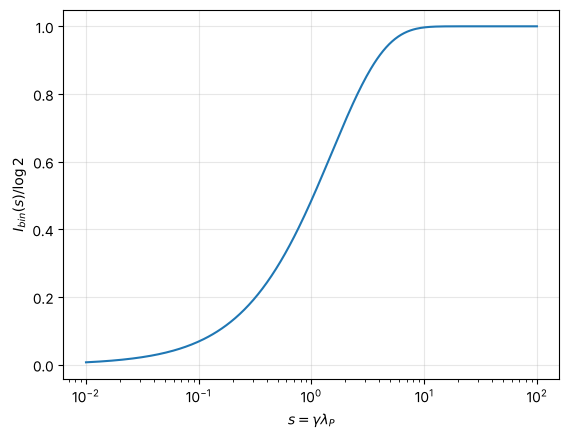

In [5]:
xs, ws = np.polynomial.hermite_e.hermegauss(120); ws = ws / ws.sum()
def Ibin(s):
    s = np.atleast_1d(s)[:, None]
    return np.log(2) - (np.logaddexp(0, -2 * (s + np.sqrt(s) * xs[None, :])) * ws).sum(1)
from scipy.optimize import brentq
for frac in (0.1, 0.5, 0.9):
    print(f'I_bin(s) = {frac:.0%} of log 2 at s = {brentq(lambda s: Ibin(s)[0] / np.log(2) - frac, 1e-4, 50):.3f}')
ss = np.geomspace(1e-2, 1e2, 300)
plt.semilogx(ss, Ibin(ss) / np.log(2)); plt.xlabel('$s=\\gamma\\lambda_P$'); plt.ylabel('$I_{bin}(s)/\\log 2$'); plt.grid(alpha=.3); plt.show()

## 5. Split variance is bounded by the parent's leading eigenvalue (Eq. `splitvar`)

In [6]:
rng = np.random.default_rng(2); worst = 0
for trial in range(2000):
    n, N = 40, 6
    Ycfg = rng.choice([-1.0, 1.0], (n, N)); p = rng.dirichlet(np.ones(n)); side = rng.random(n) < 0.5
    if side.all() or (~side).all(): continue
    w1, w2 = p[side].sum(), p[~side].sum()
    m1, m2 = p[side] @ Ycfg[side] / w1, p[~side] @ Ycfg[~side] / w2
    Delta = w1 * w2 * np.sum((m1 - m2) ** 2)
    m = p @ Ycfg; C = (Ycfg * p[:, None]).T @ Ycfg - np.outer(m, m)
    worst = max(worst, Delta / np.linalg.eigvalsh(C)[-1])
print('max Delta / lambda_P over 2000 random measures and splits: %.4f (<= 1)' % worst)

max Delta / lambda_P over 2000 random measures and splits: 0.6440 (<= 1)
